# T3: What does my model rely on? Feature importance and data curation
### Building features from the mass table, and importance tools tested on the capture data of T1

**Why this notebook.** In T1 you asked a tree which features it used and got three bars. For your own project you must decide two things with evidence: **which features to give the model**, and **which measurements to train it on**. This week is about the first; the second follows next week.
A family of tools claims to help: built-in importance, permutation importance, SHAP, LIME and others. They are powerful and easy to misread. This notebook teaches you to test them before you trust them.

**What you will do** (about 5 hours)

| Part | Content | Code given | Time |
|---|---|---|---|
| A | Building features from the mass table, then six importance tools on the capture data of T1, each with a worked example and an exercise, and your own choice of features | most of it | 4.5 h |
| D | An open question on importance tools: this week you choose it and plan it; the investigation is done next week | none | 0.5 h |

**Three rules that hold for every number you produce.** They come from T1 and from the feedback on your reports.

1. **The unit of evidence is the isotope, not the point.** The capture table has 7,624 points but 83 isotopes. Every score below is computed on isotopes that the model did not train on, and every interval is taken over isotopes.
2. **Nothing is chosen with the test isotope in view.** Features, settings and cleaning rules are fixed before the target is scored.
3. **A number has a unit, a comparison and an interval.** Errors are RMS factors as in T1 (10 to the power of the RMS error of log10 cross section; 1.0 is perfect, 2.0 is a factor of 2).

*Vocabulary used below:* **importance** (a number that says how much a model relies on a feature), **permutation** (shuffling a feature to break its link with the target), **held-out** (not used in training),
**fold** (one of the groups in a cross-validation), **attribution** (a split of one prediction into contributions of the features), **surrogate** (a simple model fitted to imitate a complicated one), **curation** (deciding which data enter the training table).

**To run it.** `numpy`, `pandas`, `matplotlib`, `scikit-learn` and `xgboost`, as in T1, and in addition the **`shap` package, which is required**: install it once with `pip install shap`. Nothing else is needed. The cells as given run in about two minutes.

# Part A. Importance tools, tested on the capture data

## A1. The data, the model and the unit of evidence
We use the table of T1 with its ten features, and one model throughout Part A: XGBoost with fixed, moderate settings. Tuning is not the subject here, so the settings stay as they are.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from pathlib import Path
from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge

D = Path("../data/teaching") if Path("../data/teaching").exists() else Path("data/teaching")   # works from notebooks/ or from the repository root
db = pd.read_csv(D / "capture_cleaned.csv").merge(pd.read_csv(D / "isotope_features.csv"), on=["Z", "A"])
db["logE"] = np.log10(db.energy_eV)             # log10 of the energy in eV
db["logS"] = np.log10(db.sigma_b * 1000)        # log10 of the cross section in millibarns
db["iso"] = db.Z * 1000 + db.A                  # one label per isotope: gold-197 is 79197

features3 = ["Z", "A", "logE"]
features10 = features3 + ["N", "Q_capture", "S_n", "B_per_A", "Z_odd", "N_odd", "N_magic_dist"]
isotope_level = [f for f in features10 if f != "logE"]      # the nine features that are the same for every point of an isotope
print(f"{len(db)} points, {db.iso.nunique()} isotopes, {len(features10)} features of which {len(isotope_level)} are properties of the isotope")

7624 points, 83 isotopes, 10 features of which 9 are properties of the isotope


**Cross-validation over isotopes.** We split the 83 isotopes into five groups (**folds**). Each fold is held out in turn and predicted by a model trained on the other four, so every isotope is predicted once by a model that never saw it.
We deal the isotopes out to the folds by hand (sorted by Z and A, one to each fold in turn). scikit-learn's `GroupKFold`, which you know from the T1 solutions, does the same job, but its assignment of isotopes to folds can change with the software version, and then your numbers would not match the ones printed here.
The three functions below are used in the whole notebook:

* `isotope_errors` returns one number per isotope: the RMS error of log10 cross section;
* `factor` turns these into one RMS factor (their geometric mean);
* `paired` compares two sets of per-isotope errors and gives a 95 % interval for the mean difference by resampling the isotopes (a **bootstrap**). If the interval contains zero, the data do not show a difference.

In [22]:
def new_model():
    return XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=0, n_jobs=4)

def isotope_folds(data, n=5):
    # deal the isotopes, sorted by Z and A, out to n groups in turn; returns (training rows, held-out rows) for each group
    group = data.iso.map({iso: k % n for k, iso in enumerate(sorted(data.iso.unique()))}).values
    return [(np.where(group != k)[0], np.where(group == k)[0]) for k in range(n)]

folds = isotope_folds(db)                                              # five groups of isotopes; an isotope is never split between training and test

def isotope_errors(feats, data=db, splits=folds):
    # RMS error of log10 sigma of every isotope, each predicted by a model that did not train on it
    out = []
    for tr, te in splits:
        model = new_model().fit(data.iloc[tr][feats], data.iloc[tr].logS)
        held = data.iloc[te]
        out.append(((model.predict(held[feats]) - held.logS) ** 2).groupby(held.iso).mean() ** 0.5)
    return pd.concat(out).sort_index()

def factor(errors):
    return 10 ** errors.mean()                                         # geometric mean of the RMS factors of the isotopes

def paired(a, b, n=2000, seed=0):
    # mean of a - b over the isotopes (log10), and its 95 % interval from resampling the isotopes
    d = (a - b).values
    rng = np.random.default_rng(seed)
    means = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

e3, e10 = isotope_errors(features3), isotope_errors(features10)
print(f"RMS factor over {len(e10)} held-out isotopes:   3 features {factor(e3):.2f}   10 features {factor(e10):.2f}")
print("difference of the log10 error, 10 features minus 3: %.3f  (95 %% interval %.3f to %.3f)" % paired(e10, e3))

RMS factor over 83 held-out isotopes:   3 features 2.97   10 features 2.21
difference of the log10 error, 10 features minus 3: -0.127  (95 % interval -0.193 to -0.069)


For this model the ten features are better than three on average, and the interval excludes zero. The typical error is still a factor of more than 2: keep that in mind when a tool below reports differences in the second decimal.

## A2. Where features come from: build them from the mass table
In T1 the seven extra features arrived ready-made in `isotope_features.csv`. For your own project nobody will hand them to you: you will build them, and you will have to decide which ones are worth giving to the model. This section shows how they are built: two worked examples, eight further features that are given, and four that you code yourself. The decision which of them to use is yours, and it is the thread of Part A.

**The source.** `nuclide_features.csv` holds 16 properties of 3,556 nuclides. It was written by `scripts/build_t3_notebook_data.py` from the AME2020 atomic mass evaluation (`data/mass_1.mas20.txt`), the standard table of measured nuclear masses. The table is already read for you; you do not need the raw file.

**The raw quantity is the mass excess.** It is the mass of the atom minus A atomic mass units, written as an energy in MeV. Because mass is energy, the energy released by any reaction is a difference of mass excesses:

energy released = (mass excesses of what goes in) $-$ (mass excesses of what comes out).

A positive value means that the reaction releases energy. Two worked examples follow. Both rebuild a feature that you used in T1, so that you can check the result.

**Worked example 1: the neutron separation energy `S_n`.** Pulling one neutron out of the nucleus (Z, A) leaves the nucleus (Z, A$-$1) and a free neutron. The energy that this *costs* is

S_n(Z, A) = ME(Z, A$-$1) + ME(neutron) $-$ ME(Z, A).

**Worked example 2: the energy released by capture, `Q_capture`.** The reaction of this table is the reverse step for the target: the nucleus (Z, A) takes up a neutron and becomes (Z, A+1), so

Q_capture(Z, A) = ME(Z, A) + ME(neutron) $-$ ME(Z, A+1).

This is the separation energy of the nucleus that is *formed*. It is the energy with which the new nucleus starts its life, and the more of it there is, the more ways the nucleus has to get rid of it by emitting gamma rays. That is a physical reason to expect that it matters for capture.

In [3]:
nuc = pd.read_csv(D / "nuclide_features.csv")                       # 16 properties of 3,556 nuclides from the AME2020 mass table
mass_excess = nuc.set_index(["Z", "A"]).mass_excess                # in MeV; mass_excess[(79, 197)] is gold-197
ME_NEUTRON = 8.0713                                                 # mass excess of the free neutron in MeV (AME2020)

built = db.drop_duplicates("iso")[["Z", "A", "S_n", "Q_capture"]].rename(columns={"S_n": "S_n_T1", "Q_capture": "Q_capture_T1"})      # the 83 isotopes with the values used in T1
built["S_n"] = [mass_excess[(z, a - 1)] + ME_NEUTRON - mass_excess[(z, a)] for z, a in zip(built.Z, built.A)]            # worked example 1
built["Q_capture"] = [mass_excess[(z, a)] + ME_NEUTRON - mass_excess[(z, a + 1)] for z, a in zip(built.Z, built.A)]      # worked example 2

g = built[(built.Z == 79) & (built.A == 197)].iloc[0]
print(f"gold-197:  S_n built {g.S_n:.3f} MeV (T1 file {g.S_n_T1:.3f});  Q_capture built {g.Q_capture:.3f} MeV (T1 file {g.Q_capture_T1:.3f})")
print(f"largest difference over the 83 isotopes:  S_n {(built.S_n - built.S_n_T1).abs().max():.4f} MeV,  Q_capture {(built.Q_capture - built.Q_capture_T1).abs().max():.4f} MeV")

gold-197:  S_n built 8.072 MeV (T1 file 8.072);  Q_capture built 6.512 MeV (T1 file 6.512)
largest difference over the 83 isotopes:  S_n 0.0001 MeV,  Q_capture 0.0001 MeV


The values built here agree with the T1 file to the rounding of the table (four decimals). The two feature files of this notebook are consistent with each other: `N`, `S_n`, `B_per_A`, `Z_odd` and `N_odd` are identical in both, and `N_magic_dist` of T1 is the column `N_valence` of the mass-table file.

**The candidates.** Besides the seven features of T1 there are twelve more. Eight are given in the next cell, one line of code each. Four are yours to code in Exercise A2: each takes a few lines and each teaches something about the raw table.

| column | meaning | who codes it |
|---|---|---|
| `mass_excess`, `binding_energy` | the raw mass excess and the total binding energy (MeV); `B_per_A` of T1 is the binding energy divided by A | given |
| `radius_fm` | nuclear radius, 1.25 A$^{1/3}$ fm | given |
| `S_2n`, `S_2p` | energy to remove two neutrons, two protons (MeV) | given |
| `Q_na` | energy released by the reaction (n,$\alpha$) on this nucleus (MeV); negative means that the reaction has a threshold | given |
| `Z_valence` | distance of Z from the nearest closed shell (magic number) | given |
| `P_factor` | N_valence $\times$ Z_valence / (N_valence + Z_valence), a measure of how far the nucleus is from closed shells in both N and Z | given |
| `S_p` | energy to remove one proton (MeV) | **you** |
| `Q_np` | energy released by the reaction (n,p) (MeV) | **you** |
| `N_valence` | distance of N from the nearest closed shell | **you** |
| `asymmetry` | the neutron excess (N $-$ Z) / A | **you** |

In [4]:
# GIVEN: eight candidate features that you do not have to code. One line each; the comment says what it is and where it comes from.
table = nuc.set_index(["Z", "A"])                                   # the mass-table file, one row per nuclide
key = pd.MultiIndex.from_frame(db[["Z", "A"]])                      # the (Z, A) of every measured point, to look values up in the table
ME_HYDROGEN = 7.2890                                                # mass excess of the hydrogen atom in MeV (AME2020)

db["mass_excess"] = table.mass_excess.reindex(key).values                             # the raw column of the mass table, MeV
db["binding_energy"] = db.Z * ME_HYDROGEN + db.N * ME_NEUTRON - db.mass_excess        # mass of the separate nucleons minus mass of the nucleus, MeV: computed here from the mass excess
db["radius_fm"] = 1.25 * db.A ** (1 / 3)                                              # nuclear radius in fm: from A alone, no table needed
db["S_2n"] = table.S_2n.reindex(key).values                                           # ME(Z, A-2) + 2 ME(n) - ME(Z, A), MeV: read from the file
db["S_2p"] = table.S_2p.reindex(key).values                                           # ME(Z-2, A-2) + 2 ME(H) - ME(Z, A), MeV: read from the file
db["Q_na"] = table.Q_na.reindex(key).values                                           # ME(Z, A) + ME(n) - ME(Z-2, A-3) - ME(helium-4), MeV: read from the file
db["Z_valence"] = table.Z_valence.reindex(key).values                                 # distance of Z from the nearest of 2, 8, 20, 28, 50, 82, 126: read from the file
db["P_factor"] = table.P_factor.reindex(key).values                                   # N_valence * Z_valence / (N_valence + Z_valence): read from the file

given = ["mass_excess", "binding_energy", "radius_fm", "S_2n", "S_2p", "Q_na", "Z_valence", "P_factor"]
print(f"given features appended: {given};  empty values: {int(db[given].isna().sum().sum())}")
print(f"check of one computed line: binding energy differs from the file by at most {(db.binding_energy - table.binding_energy.reindex(key).values).abs().max():.4f} MeV")

given features appended: ['mass_excess', 'binding_energy', 'radius_fm', 'S_2n', 'S_2p', 'Q_na', 'Z_valence', 'P_factor'];  empty values: 0
check of one computed line: binding energy differs from the file by at most 0.0003 MeV


**How should one decide?** The obvious way is the one of T1, section 11: add a feature, look at the error on gold, keep the feature if the error falls. Before you rely on it, look at what it says for the two features just built.

In [5]:
gold, rest = db[db.iso == 79197], db[db.iso != 79197]

def gold_factor(feats):
    # RMS factor on gold-197 of a model trained on the other 82 isotopes: the test of T1
    return 10 ** np.sqrt(np.mean((new_model().fit(rest[feats], rest.logS).predict(gold[feats]) - gold.logS) ** 2))

print("features                 gold alone   all 83 held-out isotopes")
for label, extra in (("Z, A, logE", []), ("+ S_n", ["S_n"]), ("+ Q_capture", ["Q_capture"]), ("+ S_n + Q_capture", ["S_n", "Q_capture"])):
    print(f"{label:24s}{gold_factor(features3 + extra):8.2f}{factor(isotope_errors(features3 + extra)):18.2f}")
rank = int((e3 < e3[79197]).sum()) + 1
print(f"\nwith three features gold is number {rank} of {len(e3)} isotopes when they are sorted from the smallest error to the largest;")
print(f"RMS factor of gold {10 ** e3[79197]:.2f}, of the median isotope {10 ** e3.median():.2f}, of the worst {10 ** e3.max():.0f}")

features                 gold alone   all 83 held-out isotopes
Z, A, logE                  1.27              2.97
+ S_n                       5.29              3.01
+ Q_capture                 1.43              2.35
+ S_n + Q_capture           2.48              2.36

with three features gold is number 4 of 83 isotopes when they are sorted from the smallest error to the largest;
RMS factor of gold 1.28, of the median isotope 2.59, of the worst 97


**What to notice.** The two columns do not give the same advice. Judged by gold alone, every addition is a step back. Judged by all 83 isotopes, each predicted by a model that did not see it, the picture is a different one.
Gold is one isotope, and one of the easiest: three features already predict it well, because it has close look-alikes (T1, section 10). An easy isotope has little to gain and is a poor judge of what helps the others.

**Exercise A2: code four features.** For each one write the reaction or the definition first, then a few lines of code that add the column to `db`, then the one-line check. Use `mass_excess`, `ME_NEUTRON`, `ME_HYDROGEN`, `table` and `key` from the cells above.

(a) **`S_p`**, the energy to remove one proton. What is left behind, and which atom carries the proton away? Check: `(db.S_p - table.S_p.reindex(key).values).abs().max()` should be below 0.001 MeV.
(b) **`Q_np`**, the energy released when a neutron goes in and a proton comes out. Check against `table.Q_np` in the same way. For which of the 83 isotopes is it negative, and what does that mean for the reaction?
(c) **`N_valence`**, the distance of N from the nearest of the magic numbers 2, 8, 20, 28, 50, 82, 126. Check: it must equal the column `N_magic_dist` of T1.
(d) **`asymmetry`**, (N $-$ Z) / A. There is no column to check against: instead plot it against Z for the 83 isotopes and say in one sentence what you see.

Optional: propose a feature that is in none of the files, with a physical reason why it could matter for capture, and build it.

**The question of Part A: which features should the model get, and how do you justify the choice?** Do not answer it yet. The sections A3 to A9 give you the tools, demonstrated on the ten features of T1 so that you know the baseline. In A10 you return to this question with all candidates.

In [6]:
# Exercise A2 (a) to (d): your code

## A3. Look at the features before the tools
The model works better with the ten features of T1 than with three (A1). *Which* of them does it need? We ask six tools and compare their answers. First, the nine isotope-level features are not independent. The **Spearman correlation** (the correlation of the ranks, between $-1$ and 1) over the 83 isotopes shows it.

pairs with |correlation| of 0.7 or more:
  Z            A            +1.00
  Z            N            +1.00
  Z            N_magic_dist +0.72
  A            N            +1.00
  A            S_n          -0.71
  A            N_magic_dist +0.72
  N            S_n          -0.72
  N            N_magic_dist +0.72


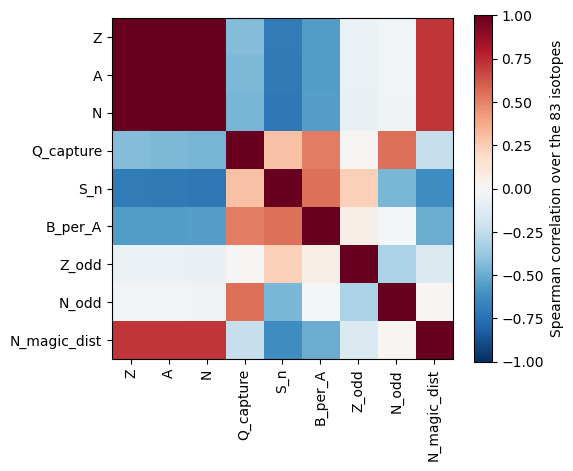

In [7]:
iso_table = db.drop_duplicates("iso").set_index("iso")[isotope_level]         # one row per isotope
rho = iso_table.corr(method="spearman")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(rho, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(rho))); ax.set_xticklabels(rho.columns, rotation=90)
ax.set_yticks(range(len(rho))); ax.set_yticklabels(rho.columns)
fig.colorbar(im, label="Spearman correlation over the 83 isotopes")

print("pairs with |correlation| of 0.7 or more:")
for i, a in enumerate(rho.columns):
    for b in rho.columns[i + 1:]:
        if abs(rho.loc[a, b]) >= 0.7:
            print(f"  {a:13s}{b:13s}{rho.loc[a, b]:+.2f}")

**What to notice.** Over these isotopes Z, A and N rank the nuclei in almost exactly the same order: for the model they are nearly one feature given three times. `S_n` and `N_magic_dist` also follow Z. Keep the group {Z, A, N} in mind: it is the reason for most of what goes wrong below.

## A4. Three numbers for the same model
We train one model on four folds and ask three questions about it.

* **Gain** (XGBoost's built-in importance, the cousin of the tree importance of T1): how much did the questions about this feature reduce the training loss?
* **Permutation importance on the training rows:** shuffle one feature, so that it no longer belongs to its row, and measure how much the error grows.
* **Permutation importance on held-out isotopes:** the same, measured on the fifth fold that the model never saw.

The unit of the two permutation columns is the rise of the RMS error of log10 cross section.

In [8]:
tr, te = folds[0]
train, held = db.iloc[tr], db.iloc[te]
model = new_model().fit(train[features10], train.logS)

def permutation(df):
    return permutation_importance(model, df[features10], df.logS, n_repeats=5, random_state=0, scoring="neg_root_mean_squared_error").importances_mean

three = pd.DataFrame({"gain": model.feature_importances_, "perm_train": permutation(train), "perm_held_out": permutation(held)}, index=features10)
print(f"one model, trained on {train.iso.nunique()} isotopes, {held.iso.nunique()} held out")
print("feature          gain  perm_train  perm_held_out")
for f, r in three.iterrows():
    print(f"{f:13s}{r.gain:8.3f}{r.perm_train:12.3f}{r.perm_held_out:15.3f}")

one model, trained on 66 isotopes, 17 held out
feature          gain  perm_train  perm_held_out
Z               0.403       1.017          0.810
A               0.024       0.009          0.001
logE            0.031       0.395          0.155
N               0.005       0.000         -0.000
Q_capture       0.051       0.173          0.066
S_n             0.120       0.106          0.039
B_per_A         0.084       0.112          0.019
Z_odd           0.121       0.033          0.006
N_odd           0.023       0.000          0.000
N_magic_dist    0.140       0.117          0.001


**What to notice**

* **The three columns do not agree.** Gain puts `N_magic_dist` and `Z_odd` right behind Z. On the held-out isotopes shuffling either of them does not raise the error: the model used them a great deal in training and gains nothing from them on new isotopes. Gain describes what the model *did*, not what it *needs*.
* **Training rows flatter every feature.** The importance of the energy is more than twice as large on the training rows as on the held-out isotopes. On its own training points the model is very accurate, so any disturbance looks costly. Importance must be measured where the model will be used: on isotopes it has not seen.
* **Z takes everything and A and N nothing.** That cannot be a statement about physics, since the three are nearly the same feature (A3). It is a statement about which of three equivalent columns the model happened to pick.

There is a further defect in the last two columns. Shuffling **rows** gives a point of gold the Z of another point: it creates nuclei that do not exist (Z of tin with A of gold), and it treats 7,624 points as if they were independent. The next section repairs both.

## A5. Shuffle isotopes, and shuffle correlated features together
Two changes. First, we swap the values **between isotopes**: every point of an isotope receives the same donor's value, as if the isotope had been given another isotope's property. Second, we can swap a **block** of features together, so that Z, A and N stay consistent with each other.
We do it for all five folds, each with its own model, and print the mean over the folds and the range: the range shows how much the answer depends on which isotopes happen to be held out.

In [9]:
fold_models = [(new_model().fit(db.iloc[tr][features10], db.iloc[tr].logS), db.iloc[te]) for tr, te in folds]      # five models, each with its held-out isotopes

def block_importance(block, n_repeats=20, seed=0):
    # rise of the RMS error (log10) on held-out isotopes when the features in `block` are swapped between isotopes; one value per fold
    rng = np.random.default_rng(seed)
    out = []
    for model, held in fold_models:
        rmse = lambda df: np.sqrt(np.mean((model.predict(df[features10]) - df.logS) ** 2))
        values = held.drop_duplicates("iso").set_index("iso")[block]                 # one row per held-out isotope
        rise = []
        for _ in range(n_repeats):
            donor = dict(zip(values.index, rng.permutation(values.index)))           # every isotope receives the values of another one
            swapped = held.copy()
            swapped[block] = values.loc[held.iso.map(donor)].values
            rise.append(rmse(swapped) - rmse(held))
        out.append(np.mean(rise))
    return np.array(out)

print("block                       mean    lowest fold  highest fold")
for block in (["Z"], ["A"], ["N"], ["Z", "A", "N"], ["Q_capture"], ["Z_odd"]):
    r = block_importance(block)
    print(f"{' + '.join(block):24s}{r.mean():8.3f}{r.min():12.3f}{r.max():13.3f}")

block                       mean    lowest fold  highest fold
Z                          0.651       0.458        0.761
A                          0.014      -0.010        0.046
N                          0.001      -0.006        0.016
Z + A + N                  0.640       0.483        0.749
Q_capture                  0.116       0.052        0.176
Z_odd                      0.005       0.003        0.012


**What to notice**

* The block {Z, A, N} is about as important as Z alone, and A and N alone are close to zero. The model put the information of the block into one column. Report the **block**, not its members.
* The folds disagree: with about 17 isotopes in a fold, the importance of the same feature changes by a factor of 1.5 to 3 from one fold to the next (compare the lowest and the highest fold of Z and of `Q_capture`). An importance without a spread over isotopes is not a result.

**Exercise A5.** (a) Add the blocks {`Q_capture`, `S_n`, `B_per_A`} (the energetics), {`Z_odd`, `N_odd`} (the parities), `N_magic_dist`, and all nine isotope-level features together. (b) Which blocks are clearly above zero in every fold? (c) In one or two sentences: why is "all nine together" not the sum of the parts?

In [10]:
# Exercise A5: your code

## A6. Drop-column: the test that answers the question
Permutation asks *"what happens if I disturb a feature of a trained model?"*. Your decision is a different one: *"should I give this feature to the model at all?"*. The direct test is to **leave it out, retrain, and compare** on held-out isotopes.
It costs one cross-validation per candidate, which takes about a second here. We compare isotope by isotope with `paired` from A1.

In [11]:
print("left out                 RMS factor   change of log10 error (95 % interval)")
print(f"{'nothing (10 features)':24s}{factor(e10):8.2f}")
for drop in (["Z"], ["Z", "A", "N"], ["Q_capture"]):
    e = isotope_errors([f for f in features10 if f not in drop])
    print(f"{' + '.join(drop):24s}{factor(e):8.2f}        %+.3f  (%+.3f to %+.3f)" % paired(e, e10))

left out                 RMS factor   change of log10 error (95 % interval)
nothing (10 features)       2.21
Z                           2.25        +0.007  (-0.012 to +0.030)
Z + A + N                   3.09        +0.144  (+0.083 to +0.221)
Q_capture                   2.60        +0.070  (+0.026 to +0.128)


**What to notice**

* **Z was the most important feature by every measure so far, and the model does not need it.** Without Z the error is unchanged within the interval: A and N carry the same information and take over. *Important to a trained model* and *necessary* are different statements. Only the second one tells you what to keep.
* Leaving out the whole block {Z, A, N} does cost accuracy, and so does `Q_capture`, the one feature here that says something Z, A and N do not.

**Exercise A6.** (a) Extend the table to every single feature and to the blocks of Exercise A5. (b) Is there a feature whose removal *improves* the model, with an interval that excludes zero? (c) You have just judged features using all 83 isotopes. If gold-197 were your target, would this selection be allowed? What would you have to change? (Rule 2 of the introduction; you will need the answer next week.)

In [12]:
# Exercise A6: your code

## A7. SHAP: splitting one prediction into contributions
The tools so far give one number per feature for the whole model. **SHAP** (SHapley Additive exPlanations) explains a **single prediction**: it starts from the average prediction of the model (the **base value**) and gives every feature a contribution, positive or negative, such that

prediction = base value + sum of the contributions.

For tree models the contributions can be computed exactly and fast (TreeSHAP). XGBoost has the calculation built in (`pred_contribs=True`), and the `shap` package computes the same numbers and draws the standard pictures. We use the built-in one for tables and `shap` for plots.
We explain the prediction for gold-197 at 1 MeV by a model that was trained **without gold**. The unit of every contribution is log10 of the cross section: +0.3 means "this feature raised the prediction by a factor of 2".

In [13]:
def shap_table(model, df, feats):
    # one row per point, one column per feature plus 'base'; the columns of a row add up to the prediction (log10 mb)
    contributions = model.get_booster().predict(xgb.DMatrix(df[feats]), pred_contribs=True)
    return pd.DataFrame(contributions, columns=feats + ["base"], index=df.index)

model_gold = new_model().fit(rest[features10], rest.logS)                     # trained without gold
point = gold.iloc[[np.argmin(np.abs(gold.logE - 6.0))]]                       # the gold point nearest 1 MeV
c = shap_table(model_gold, point, features10).iloc[0]

print(f"gold-197 at {10 ** point.logE.iloc[0] / 1e6:.2f} MeV: base value {c.base:.3f} + contributions {c.drop('base').sum():+.3f} = {c.sum():.3f}")
print(f"prediction of the model {model_gold.predict(point[features10])[0]:.3f}   measured {point.logS.iloc[0]:.3f}   (log10 of mb)")

explanation = shap.TreeExplainer(model_gold)(point[features10])              # the same calculation with the shap package
print(f"largest difference between the shap package and XGBoost's own contributions: {np.abs(explanation.values[0] - c.drop('base').values).max():.1e}")
shap.plots.waterfall(explanation[0], show=False)                              # from the base value (bottom) to the prediction (top), one bar per feature
plt.title("SHAP waterfall: gold-197 at 1 MeV, model trained without gold")

gold-197 at 1.00 MeV: base value 1.327 + contributions +0.816 = 2.144
prediction of the model 2.144   measured 1.954   (log10 of mb)
largest difference between the shap package and XGBoost's own contributions: 0.0e+00


Text(0.5, 1.0, 'SHAP waterfall: gold-197 at 1 MeV, model trained without gold')

The contributions add up to the prediction exactly: SHAP is bookkeeping of what the model computed. A global importance follows by averaging the absolute contributions over many points. As in A4, it matters *which* points: we use the held-out isotopes of each fold, and the training isotopes for comparison.

In [14]:
held_out = pd.concat([shap_table(m, h, features10) for m, h in fold_models]).drop(columns="base").abs()              # every isotope explained by a model that did not see it
per_fold = pd.DataFrame([shap_table(m, h, features10).drop(columns="base").abs().mean() for m, h in fold_models])
training = pd.DataFrame([shap_table(m, db.drop(h.index), features10).drop(columns="base").abs().mean() for m, h in fold_models]).mean()

print("mean |SHAP| (log10)  held-out  lowest fold  highest fold  training isotopes")
for f in features10:
    print(f"{f:16s}{held_out[f].mean():12.3f}{per_fold[f].min():13.3f}{per_fold[f].max():14.3f}{training[f]:19.3f}")

rows = pd.concat([h for _, h in fold_models])                                    # all 83 isotopes, each with the model that did not see it
values = pd.concat([shap_table(m, h, features10) for m, h in fold_models])[features10].values
shap.summary_plot(values, rows[features10], show=False)                         # one dot per measured point: position is the contribution, colour the value of the feature
plt.title("SHAP summary on held-out isotopes")
shap.dependence_plot("Q_capture", values, rows[features10], interaction_index="Z", show=False)      # contribution of Q_capture against its value, coloured by Z
plt.title("SHAP dependence of Q_capture on held-out isotopes")

mean |SHAP| (log10)  held-out  lowest fold  highest fold  training isotopes
Z                      0.615        0.458         0.730              0.629
A                      0.017        0.007         0.031              0.019
logE                   0.215        0.190         0.229              0.236
N                      0.010        0.003         0.019              0.011
Q_capture              0.162        0.133         0.202              0.163
S_n                    0.081        0.037         0.126              0.079
B_per_A                0.102        0.086         0.130              0.109
Z_odd                  0.033        0.020         0.045              0.032
N_odd                  0.001        0.000         0.001              0.001
N_magic_dist           0.144        0.027         0.415              0.130


Text(0.5, 1.0, 'SHAP dependence of Q_capture on held-out isotopes')

**How to read the two plots.** In the summary plot every row is a feature and every dot a measured point; a dot far from zero is a point whose prediction this feature moved a long way. In the dependence plot the dots stand in vertical stripes: a feature of the isotope takes only 83 different values, one per isotope, however many points there are.

**What SHAP is and is not**

* It explains **the model**, not the nucleus. The large contribution of Z for gold says that the model's rules lead from Z = 79 to a high cross section. It does not say that charge causes capture.
* With correlated features the split is as arbitrary as in A4: Z receives the credit of the block {Z, A, N}. Add the contributions of a block before you interpret them.
* Its strength is the **local** view: for one isotope you can see what pushed the prediction up or down, and compare isotopes. That is useful for finding out *why* a prediction is wrong.

**Exercise A7.** (a) Compute the SHAP table of all gold points (model without gold) and plot the contribution of `logE` against the energy. What has the model learned about the energy dependence? (b) Add the contributions of the block {Z, A, N} for each held-out isotope, and plot the block contribution against Z, one dot per isotope. How many independent dots are there?
(c) Optional: pick the isotope with the largest error in `e10` and compare its SHAP contributions with those of gold. Does SHAP tell you why the model fails there?

In [15]:
# Exercise A7: your code

## A8. LIME: a local straight-line surrogate
**LIME** (Local Interpretable Model-agnostic Explanations) also explains one prediction, in a different way. It (1) draws many artificial points around the point of interest by disturbing every feature at random, (2) asks the model for its prediction at each of them, (3) gives nearby points more weight, and (4) fits a **straight-line model** to these predictions. The slopes of that line are the explanation.
The `lime` package does this with many options. The core is fifteen lines, and writing it out shows what the method assumes.
The slopes are per standard deviation of a feature, so they can be compared with each other; the unit is again log10 of the cross section.

In [16]:
def lime_by_hand(model, x, background, feats, n_samples=500, width=0.75, seed=0):
    # slopes of a weighted straight-line fit to the model around the point x (per standard deviation of each feature)
    rng = np.random.default_rng(seed)
    step = rng.normal(size=(n_samples, len(feats)))                           # random disturbances, every feature independently of the others
    samples = pd.DataFrame(x[feats].values + step * background[feats].std().values, columns=feats)
    weight = np.exp(-(step ** 2).sum(axis=1) / (2 * (width * np.sqrt(len(feats))) ** 2))      # nearby samples count more
    line = Ridge(alpha=1.0).fit(step, model.predict(samples), sample_weight=weight)
    return pd.Series(line.coef_, index=feats)

x = point.iloc[0]                                                              # gold-197 at 1 MeV, as in A7
seeds = pd.DataFrame({f"seed {s}": lime_by_hand(model_gold, x, rest, features10, seed=s) for s in range(4)})
widths = pd.DataFrame({f"width {w}": lime_by_hand(model_gold, x, rest, features10, n_samples=5000, width=w) for w in (0.25, 0.75, 2.0)})
print("LIME slopes for gold-197 at 1 MeV: four random seeds (500 samples), then three kernel widths (5000 samples), and SHAP for comparison")
print(pd.concat([seeds, widths, c.drop("base").rename("SHAP")], axis=1).round(3).to_string())

LIME slopes for gold-197 at 1 MeV: four random seeds (500 samples), then three kernel widths (5000 samples), and SHAP for comparison
              seed 0  seed 1  seed 2  seed 3  width 0.25  width 0.75  width 2.0   SHAP
Z              0.192   0.184   0.193   0.177       0.080       0.185      0.214  0.846
A             -0.069  -0.051  -0.061  -0.055      -0.055      -0.054     -0.052 -0.030
logE          -0.494  -0.435  -0.445  -0.492      -0.441      -0.464     -0.453 -0.240
N              0.016  -0.002  -0.016  -0.012       0.006      -0.000     -0.002 -0.007
Q_capture      0.147   0.187   0.173   0.144       0.156       0.153      0.149 -0.019
S_n           -0.009  -0.004  -0.041  -0.010      -0.046      -0.018     -0.014  0.088
B_per_A        0.026  -0.036   0.008   0.015       0.013      -0.009     -0.015  0.128
Z_odd          0.045  -0.007   0.049   0.013       0.054       0.036      0.036  0.058
N_odd         -0.009   0.006  -0.012  -0.011      -0.004      -0.000      0.002  0.0

**What to notice**

* **LIME and SHAP answer different questions.** SHAP says how far each feature moved this prediction away from the average prediction. LIME says how the prediction would change if the feature were changed a little. For gold the energy has the steepest local slope, while Z has the largest SHAP contribution. Neither is wrong.
* **The explanation depends on choices that are not part of the model:** the random seed, the number of samples and the width of the neighbourhood. Compare the columns.
* **The artificial points are not nuclei.** Every feature is disturbed independently, so LIME asks the model about a nucleus with Z = 81.3, A = 190 and `Z_odd` = 0.4. The model answers, because a tree model answers anything, but the answer describes a region where there are no data.

**Exercise A8.** (a) Quantify the stability: for 30 seeds, compute the standard deviation of each slope for 100, 500 and 5000 samples. How many samples are needed before the ranking of the three largest slopes stops changing? (b) State in two sentences when you would use LIME, when SHAP, and when neither.

In [17]:
# Exercise A8: your code

## A9. Which training isotopes carry the prediction?
All tools so far ask about **columns**. Curation is mostly about **rows**: which data should the model learn from? T1 showed that the prediction for gold rests on a few look-alike isotopes.
The direct way to measure the **influence** of a training isotope is the one used in A6 for features: leave it out, retrain, and see how the prediction for the target moves. That is 82 short trainings.

In [18]:
base = model_gold.predict(gold[features10])                                    # prediction for gold with all 82 training isotopes
influence = {}
for i in rest.iso.unique():                                                    # leave one training isotope out at a time
    without = rest[rest.iso != i]
    influence[i] = np.mean(new_model().fit(without[features10], without.logS).predict(gold[features10]) - base)
influence = pd.Series(influence).sort_values()

name = lambda i: f"Z={i // 1000}, A={i % 1000}"
print(f"error of the gold prediction with all training isotopes: RMS factor {10 ** np.sqrt(np.mean((base - gold.logS) ** 2)):.2f}")
print("shift of the gold prediction (mean of log10) when one training isotope is left out")
for i, v in pd.concat([influence.head(4), influence.tail(4)]).items():
    print(f"  {name(i):16s}{v:+.3f}")
ax = influence.reset_index(drop=True).plot(figsize=(6, 2.8), marker=".", ls="")
ax.axhline(0, color="k", lw=0.8); ax.grid(alpha=0.3)
ax.set(xlabel="training isotopes, sorted", ylabel="shift of log10 prediction", title="Influence of each training isotope on the gold prediction")

error of the gold prediction with all training isotopes: RMS factor 2.08
shift of the gold prediction (mean of log10) when one training isotope is left out
  Z=73, A=181     -0.109
  Z=30, A=64      -0.107
  Z=57, A=139     -0.097
  Z=59, A=141     -0.092
  Z=70, A=170     +0.025
  Z=39, A=89      +0.026
  Z=66, A=160     +0.050
  Z=77, A=193     +0.093


[Text(0.5, 0, 'training isotopes, sorted'),
 Text(0, 0.5, 'shift of log10 prediction'),
 Text(0.5, 1.0, 'Influence of each training isotope on the gold prediction')]

**What to notice.** Most training isotopes do not matter for gold at all, and a handful move the prediction by tens of per cent. The model's answer for an unmeasured isotope is, to a large part, the answer of its neighbours.
If one of those neighbours carries a wrong dataset, the error goes straight into the prediction. That is why curation (next week) matters most for the neighbours of your target.

**Exercise A9.** (a) Are the most influential isotopes the look-alikes of T1 (section 10)? Compare their Z and A with gold. (b) The mean shift hides the sign of the effect on the *error*: for the four most influential isotopes, does leaving them out make the gold prediction better or worse?
(c) A warning to discuss in one sentence: if you removed training isotopes *because* that improves the score on gold, what would you have done?

## A10. Your feature choice
Return to the question of A2: **which features should the model get?** You now have the candidates (the seven of T1, the eight given in A2 and the four you coded) and the tools.

**Requirements for a valid answer**

1. **Write down your decision rule before you apply it**, for example "a feature or block stays if leaving it out raises the error with an interval that excludes zero". State it in one or two sentences.
2. The evidence is taken over **held-out isotopes, on all 83** (`isotope_errors`, `factor`, `paired`), never on gold alone.
3. Use at least block permutation over isotopes (A5), drop-column with intervals (A6) and SHAP on held-out isotopes (A7). Group correlated candidates into blocks first (A3); several candidates are close relatives of Z, A and N.
4. Report: your feature set; its RMS factor over the 83 isotopes; the paired interval against the three features and against the ten of T1; and what the gold test alone would have said about your set.
5. One paragraph: where the tools disagreed, which one you followed and why. And one sentence: if gold-197 were your target isotope, which step of your procedure would have to change?

There is no single correct set. A short set with clear evidence is a better answer than a long one without.

In [19]:
# A10: your code

### Summary of Part A

| Tool | Question it answers | Trust it for | Main trap here |
|---|---|---|---|
| Gain or impurity | What did training use? | a first look | rewards features that help memorise isotopes |
| Permutation, rows | What does the trained model lean on? | little, in this problem | impossible nuclei; points are not independent |
| Permutation, isotopes and blocks | The same, without those defects | ranking blocks of features | the spread between folds is large |
| Drop-column over isotopes | Should I keep this feature? | **feature selection** | must be done without the test isotope |
| SHAP | Why this prediction? | diagnosing single isotopes | credit inside a correlated block is arbitrary |
| LIME | How does the prediction change nearby? | rarely, for isotope-level features | depends on seed and width; samples are not nuclei |
| Leave-one-isotope-out influence | Which training data carry this prediction? | **curation**, finding look-alikes | tempting to tune the training set on the target |

# Part D. An open question on importance tools

Importance tools are widely used on nuclear data, and it is not well established how far they can be trusted on tables like ours, where features are properties of isotopes and a few dozen isotopes are all there is.
Your results here are of direct use to the research of the group. **This week you only choose and plan:** pick **one** question, or propose your own, and write five lines: the question, the data table, the method, what would count as an answer, and what you expect. The investigation itself is the work of next week. A negative result ("the tool is not stable enough to use") is as valuable as a positive one.

1. **Do the tools agree across models?** Train a random forest and a single tree next to XGBoost on the same folds. Do block permutation, drop-column and SHAP (scikit-learn forests are supported by the `shap` package; or use drop-column and permutation only) give the same ranking of the *blocks*? Where they disagree, which do you believe and why?
2. **Does an importance ranking survive a change of isotopes?** Resample the isotopes (bootstrap) 30 times and recompute a ranking. How often does each feature appear in the top three? Is there any ranking statement that holds in at least 90 % of the resamples?
3. **Is LIME stable enough to use?** Extend Exercise A8 to ten isotopes and to the `lime` package if you install it. Give a rule: number of samples and width for which two runs agree, or the statement that there is none.
4. **Does the answer of Part A depend on the mass region?** Repeat A6 separately for the 30 lightest and the 30 heaviest capture isotopes. (Most relevant for the reactor project.)

In [20]:
# Part D: nothing to run this week; write your five-line plan in a markdown cell below